<a href="https://colab.research.google.com/github/CosmasHW/Tugas_P6/blob/main/naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes — Titanic Dataset



## 1. Importing the libraries

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

## 2. Importing and cleaning the dataset

In [16]:
dataset = pd.read_csv('titanic.csv')
print('Shape awal:', dataset.shape)
print(dataset.dtypes)
dataset.head()

Shape awal: (891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [17]:
dataset = dataset.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

dataset['Sex']      = dataset['Sex'].map({'male': 0, 'female': 1})
dataset['Embarked'] = dataset['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

print(dataset.dtypes)
print('Kolom object tersisa:', dataset.select_dtypes(include='object').columns.tolist())

Survived      int64
Pclass        int64
Sex           int64
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked    float64
dtype: object
Kolom object tersisa: []


## 3. Selecting features & target

In [18]:
X = dataset[['Age', 'Fare']].values
y = dataset['Survived'].values

print('X shape:', X.shape)
print('y shape:', y.shape)
print('NaN di X (sebelum impute):', np.isnan(X).sum())
print(X[:5])
print(y[:5])

X shape: (891, 2)
y shape: (891,)
NaN di X (sebelum impute): 177
[[22.      7.25  ]
 [38.     71.2833]
 [26.      7.925 ]
 [35.     53.1   ]
 [35.      8.05  ]]
[0 1 1 1 0]


## 4. Imputing missing values


In [19]:
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X)

print('NaN di X (setelah impute):', np.isnan(X).sum())
assert np.isnan(X).sum() == 0, 'NaN di X!'

NaN di X (setelah impute): 0


## 5. Splitting the dataset into the Training set and Test set

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (668, 2)
X_test : (223, 2)
y_train: (668,)
y_test : (223,)


## 6. Feature Scaling

In [21]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test  = sc.transform(X_test)

print('X_train[:3]:')
print(X_train[:3])
print('X_test[:3]:')
print(X_test[:3])

X_train[:3]:
[[-0.11727262 -0.48380773]
 [-0.96500423 -0.48323058]
 [ 0.0368604  -0.32165051]]
X_test[:3]:
[[-0.11727262 -0.35409895]
 [-0.11727262 -0.49064251]
 [-1.73566933 -0.06420947]]


## 7. Training the Naive Bayes model

In [22]:
classifier = GaussianNB()
classifier.fit(X_train, y_train)

from sklearn.utils.validation import check_is_fitted
check_is_fitted(classifier)
print('Classifier type :', type(classifier).__name__)
print('Classifier siap.' )

Classifier type : GaussianNB
Classifier siap.


## 8. Predicting the Test set results

In [23]:
y_pred = classifier.predict(X_test)

print('y_pred[:10]:', y_pred[:10])
print('y_test[:10]:', y_test[:10])
print('Accuracy   :', accuracy_score(y_test, y_pred))

y_pred[:10]: [0 0 0 1 0 0 1 1 1 0]
y_test[:10]: [0 0 0 1 1 1 1 1 1 1]
Accuracy   : 0.695067264573991


## 9. Confusion Matrix & Classification Report

Confusion Matrix:
[[134   5]
 [ 63  21]]


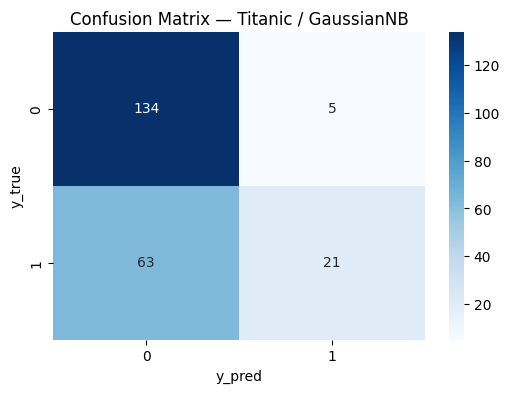

In [24]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

f, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=ax)
ax.set_xlabel('y_pred')
ax.set_ylabel('y_true')
ax.set_title('Confusion Matrix — Titanic / GaussianNB')
plt.show()

In [25]:
print(classification_report(y_test, y_pred, target_names=['Not Survived (0)', 'Survived (1)']))

                  precision    recall  f1-score   support

Not Survived (0)       0.68      0.96      0.80       139
    Survived (1)       0.81      0.25      0.38        84

        accuracy                           0.70       223
       macro avg       0.74      0.61      0.59       223
    weighted avg       0.73      0.70      0.64       223



## 10. Visualising the Training set results

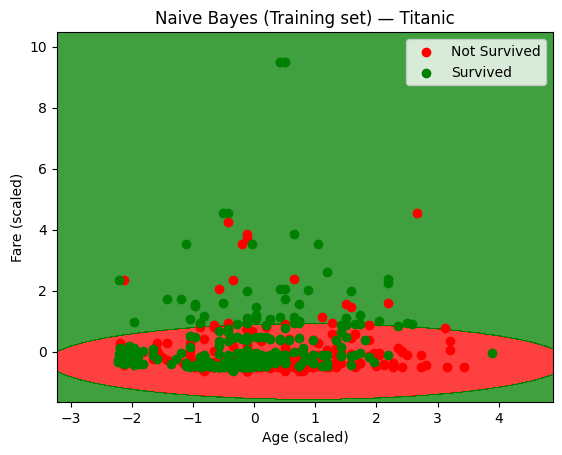

In [26]:
def plot_decision_boundary(X_set, y_set, classifier, title):
    X1, X2 = np.meshgrid(
        np.arange(start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01),
        np.arange(start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01)
    )
    plt.contourf(
        X1, X2,
        classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.75, cmap=ListedColormap(('red', 'green'))
    )
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(
            X_set[y_set == j, 0], X_set[y_set == j, 1],
            color=ListedColormap(('red', 'green'))(i),
            label=('Not Survived' if j == 0 else 'Survived')
        )
    plt.title(title)
    plt.xlabel('Age (scaled)')
    plt.ylabel('Fare (scaled)')
    plt.legend()
    plt.show()

plot_decision_boundary(X_train, y_train, classifier, 'Naive Bayes (Training set) — Titanic')

## 11. Visualising the Test set results

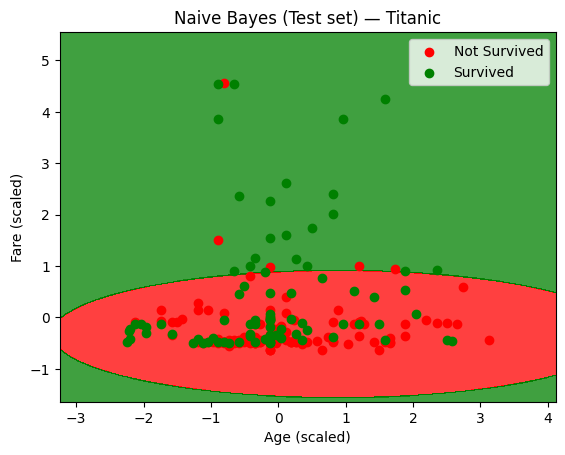

In [27]:
plot_decision_boundary(X_test, y_test, classifier, 'Naive Bayes (Test set) — Titanic')

## 12. Final sanity check

In [28]:
print('NaN di X_train :', np.isnan(X_train).sum())
print('NaN di X_test  :', np.isnan(X_test).sum())
print('NaN di y_train :', np.isnan(y_train).sum())
print('Accuracy       :', accuracy_score(y_test, y_pred))

assert np.isnan(X_train).sum() == 0
assert np.isnan(X_test).sum() == 0
assert np.isnan(y_train).sum() == 0

pd.DataFrame({'y_true': y_test, 'y_pred': y_pred}).to_csv(
    'titanic_nb_predictions.csv', index=False)


NaN di X_train : 0
NaN di X_test  : 0
NaN di y_train : 0
Accuracy       : 0.695067264573991
